# Πώς δουλεύει ο αλγόριθμος pairs trading

Αυτό το notebook εξηγεί βήμα-βήμα τι κάνει το bot σου, πάνω σε **πραγματικά δεδομένα** ενός από τα ζεύγη που παρακολουθεί.

**Η ιδέα σε μία πρόταση:** βρίσκουμε δύο νομίσματα που κινούνται μαζί. Όταν απομακρυνθούν ασυνήθιστα πολύ το ένα από το άλλο, αγοράζουμε το «φθηνό», πουλάμε (short) το «ακριβό» και περιμένουμε να ξαναπλησιάσουν. Δεν μας ενδιαφέρει αν η αγορά ανεβαίνει ή πέφτει, μόνο η **απόσταση** ανάμεσα στα δύο.

Περιεχόμενα:
1. Τα δεδομένα του ζεύγους
2. Η σχέση των δύο νομισμάτων (παλινδρόμηση)
3. Το spread: πόσο έχουν απομακρυνθεί
4. Το Z-score: πόσο *ασυνήθιστη* είναι η απομάκρυνση
5. Κανόνες εισόδου και εξόδου
6. Πόσα αγοράζουμε από το καθένα
7. Διαχείριση κινδύνου
8. Backtest του ζεύγους: πώς θα είχε πάει
9. Πώς διαλέχτηκαν τα ζεύγη (funnel)
10. Το χαρτοφυλάκιο συνολικά
11. **Το bot ζωντανά**: τι κάνει αυτή τη στιγμή

> Για να το τρέξεις: πάνω από το μενού επίλεξε **Run → Run All Cells**. Για άλλο ζεύγος, άλλαξε το `PAIR` στο επόμενο κελί.

In [1]:
import os, sys, math, json, sqlite3
from pathlib import Path
# το notebook βρίσκεται στο notebooks/, ο κώδικας του bot ένα επίπεδο πάνω
ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
os.chdir(ROOT); sys.path.insert(0, str(ROOT))

import numpy as np, pandas as pd, matplotlib.pyplot as plt, yaml
from cryptopairs.config import load_config, HOUR_MS
from cryptopairs.core.signals import rolling_ols, fit_ols
from cryptopairs.core.sizing import target_quantities
from cryptopairs.core.strategy import PairParams
from cryptopairs.research.data import DataStore, load_pair
from cryptopairs.research.backtest import run_backtest

plt.rcParams["figure.figsize"] = (12, 4); plt.rcParams["axes.grid"] = True

cfg = load_config("config/config.yaml", "hardened")   # οι ρυθμίσεις με τις οποίες τρέχει το bot
pairs = yaml.safe_load(open("runs/hardened/pairs.yaml"))["pairs"]

PAIR = "SFPUSDT_SSVUSDT"            # <-- άλλαξέ το σε οποιοδήποτε id από το pairs.yaml
p = next(x for x in pairs if x["id"] == PAIR)
A, B = p["a"], p["b"]
params = PairParams(p["lookback"], p["z_entry"], p["z_exit"])
print(f"Ζεύγος: {A} / {B}")
print(f"Παράμετροι: παράθυρο L = {params.lookback} ώρες ({params.lookback/24:.0f} μέρες), "
      f"είσοδος |Z| > {params.z_entry}, έξοδος στο Z = ±{params.z_exit}")
print(f"Μόχλευση {cfg.strategy.leverage}x, stop-loss {cfg.strategy.stop_loss_pct:.0%}, "
      f"stop έκτακτης ανάγκης {cfg.strategy.catastrophe_stop_pct:.0%}")

Ζεύγος: SFPUSDT / SSVUSDT
Παράμετροι: παράθυρο L = 2160 ώρες (90 μέρες), είσοδος |Z| > 1.0, έξοδος στο Z = ±0.5
Μόχλευση 2.0x, stop-loss 20%, stop έκτακτης ανάγκης 35%


## 1. Τα δεδομένα

Χρησιμοποιούμε **ωριαίες** τιμές κλεισίματος από Binance futures. Παρακάτω οι δύο τιμές τους τελευταίους μήνες, κανονικοποιημένες ώστε να ξεκινούν από 1 και να συγκρίνονται εύκολα.

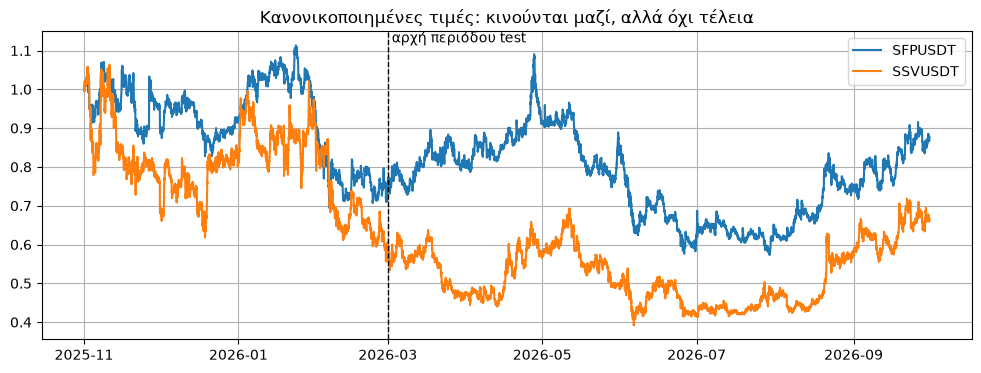

29136 ωριαία κεριά, από 2023-06-05 έως 2026-09-30


In [2]:
rc = cfg.research
data = load_pair(DataStore(Path("data")), A, B, rc.data_start_ms, rc.test_end_ms)
t = pd.to_datetime(data.ts, unit="ms")
i0 = data.window(rc.test_start_ms, rc.test_end_ms)[0]

fig, ax = plt.subplots()
ax.plot(t[i0-24*120:], data.close_a[i0-24*120:] / data.close_a[i0-24*120], label=A)
ax.plot(t[i0-24*120:], data.close_b[i0-24*120:] / data.close_b[i0-24*120], label=B)
ax.axvline(t[i0], color="k", ls="--", lw=1); ax.text(t[i0], ax.get_ylim()[1], " αρχή περιόδου test", va="top")
ax.set_title("Κανονικοποιημένες τιμές: κινούνται μαζί, αλλά όχι τέλεια"); ax.legend(); plt.show()
print(f"{len(data)} ωριαία κεριά, από {t[0]:%Y-%m-%d} έως {t[-1]:%Y-%m-%d}")

## 2. Η σχέση των δύο νομισμάτων

Υποθέτουμε ότι οι **λογάριθμοι** των τιμών συνδέονται γραμμικά:

$$\log P_A = \alpha + \beta \cdot \log P_B + u$$

- **β** (beta): πόσο % κινείται το A όταν το B κινείται 1%. Π.χ. β = 1.2 σημαίνει ότι αν το B ανέβει 10%, «κανονικά» το A ανεβαίνει ~12%.
- **α**: μια σταθερά (η «φυσιολογική» απόσταση των επιπέδων τους).
- **u**: ό,τι περισσεύει, δηλαδή πόσο *παρεκκλίνει* σήμερα το A από εκεί που «θα έπρεπε» να είναι. Αυτό είναι το **spread**.

Τα α και β τα εκτιμάμε με **παλινδρόμηση (OLS)** στις τελευταίες L ώρες. Στο διάγραμμα, κάθε τελεία είναι μία ώρα και η γραμμή είναι η εκτιμώμενη σχέση.

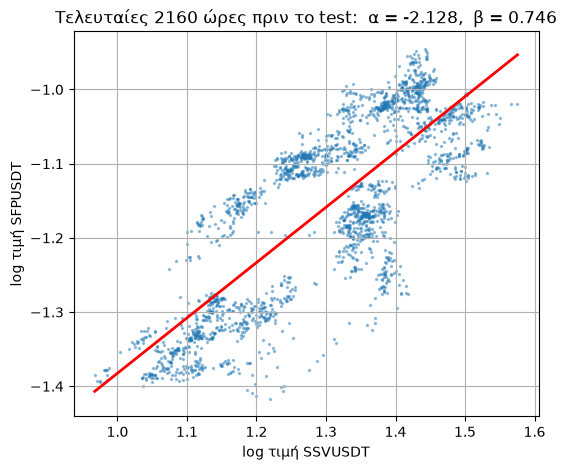

σ (τυπική απόκλιση του spread) = 0.0752, δηλαδή το spread κουνιέται συνήθως ±7.5%


In [3]:
L = params.lookback
la, lb = data.log_a[i0-L:i0], data.log_b[i0-L:i0]
alpha, beta, sigma = fit_ols(la, lb)
fig, ax = plt.subplots(figsize=(6, 5))
ax.scatter(lb, la, s=2, alpha=0.4)
xs = np.linspace(lb.min(), lb.max(), 50); ax.plot(xs, alpha + beta * xs, "r", lw=2)
ax.set_xlabel(f"log τιμή {B}"); ax.set_ylabel(f"log τιμή {A}")
ax.set_title(f"Τελευταίες {L} ώρες πριν το test:  α = {alpha:.3f},  β = {beta:.3f}"); plt.show()
print(f"σ (τυπική απόκλιση του spread) = {sigma:.4f}, δηλαδή το spread κουνιέται συνήθως ±{sigma*100:.1f}%")

## 3. Το spread

Το spread $u_t = \log P_A - \alpha - \beta \log P_B$ μετράει **πόσο έχουν απομακρυνθεί** τα δύο νομίσματα από τη φυσιολογική τους σχέση.
- **u > 0**: το A είναι *ακριβό* σε σχέση με το B
- **u < 0**: το A είναι *φθηνό* σε σχέση με το B

Τα α και β ξαναϋπολογίζονται **κάθε ώρα** με τις τελευταίες L ώρες (κυλιόμενο παράθυρο), ώστε να προσαρμόζονται καθώς αλλάζει η αγορά.

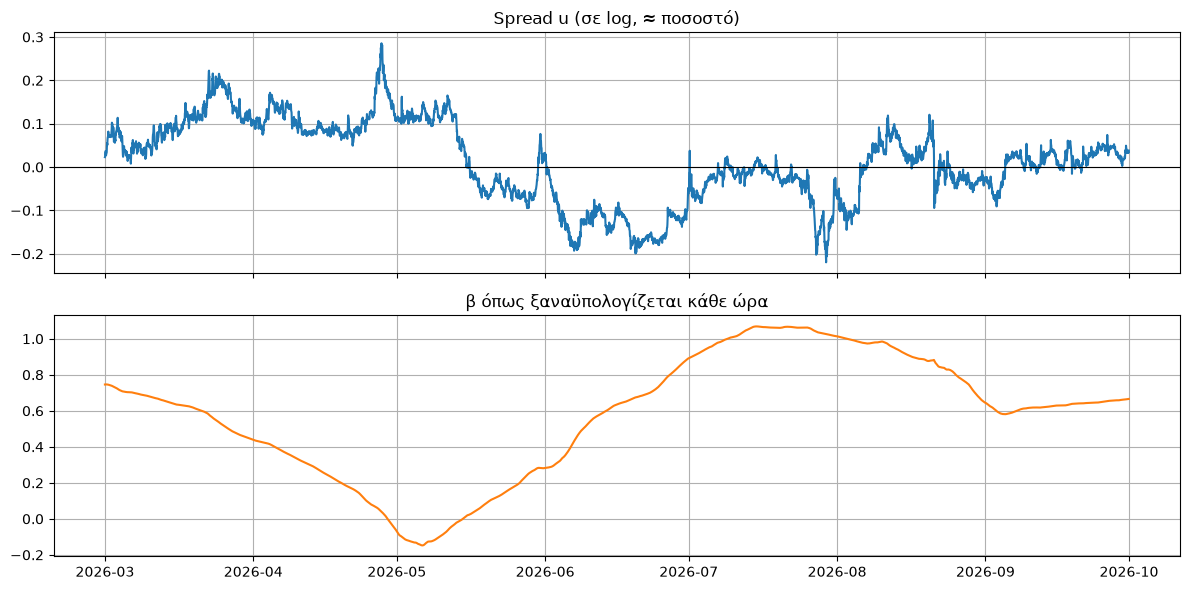

In [4]:
al, be, si = rolling_ols(data.log_a, data.log_b, L)
u = data.log_a - al - be * data.log_b
z = u / si
fig, axes = plt.subplots(2, 1, figsize=(12, 6), sharex=True)
axes[0].plot(t[i0:], u[i0:]); axes[0].axhline(0, color="k", lw=0.8); axes[0].set_title("Spread u (σε log, ≈ ποσοστό)")
axes[1].plot(t[i0:], be[i0:], color="tab:orange"); axes[1].set_title("β όπως ξαναϋπολογίζεται κάθε ώρα")
plt.tight_layout(); plt.show()

## 4. Το Z-score

Μια απόκλιση 5% μπορεί να είναι τεράστια για ένα ήρεμο ζεύγος και ασήμαντη για ένα νευρικό. Γι' αυτό τη μετράμε σε **μονάδες τυπικής απόκλισης**:

$$Z = \frac{u}{\sigma}$$

- Z = 0: όλα φυσιολογικά
- Z = +2: το A είναι ασυνήθιστα ακριβό (2 «κανονικές» αποκλίσεις πάνω)
- Z = −2: το A είναι ασυνήθιστα φθηνό

Οι οριζόντιες γραμμές δείχνουν τα όρια εισόδου (κόκκινες) και εξόδου (πράσινες) αυτού του ζεύγους.

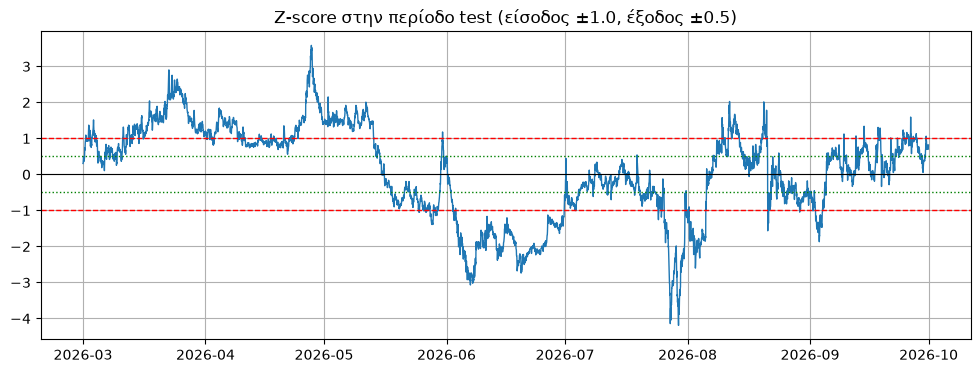

In [5]:
fig, ax = plt.subplots()
ax.plot(t[i0:], z[i0:], lw=1)
for s in (1, -1):
    ax.axhline(s * params.z_entry, color="r", ls="--", lw=1)
    ax.axhline(s * params.z_exit, color="g", ls=":", lw=1)
ax.axhline(0, color="k", lw=0.8)
ax.set_title(f"Z-score στην περίοδο test (είσοδος ±{params.z_entry}, έξοδος ±{params.z_exit})"); plt.show()

## 5. Κανόνες εισόδου και εξόδου

| Κατάσταση | Τι σημαίνει | Τι κάνει το bot |
|---|---|---|
| Z > +z_entry | A ακριβό, B φθηνό | **Short spread**: πουλάει A, αγοράζει B |
| Z < −z_entry | A φθηνό, B ακριβό | **Long spread**: αγοράζει A, πουλάει B |
| Σε long και το Z ανέβει πάνω από −z_exit | ξαναπλησίασαν | κλείνει με κέρδος |
| Σε short και το Z πέσει κάτω από +z_exit | ξαναπλησίασαν | κλείνει με κέρδος |

Όσο είναι σε θέση, το bot **δεν** ξαναϋπολογίζει τα α, β, σ (τα «παγώνει»), ώστε να μετράει το κέρδος με τους ίδιους όρους που μπήκε.

Στο live, το Z υπολογίζεται με τις τιμές που *πραγματικά* μπορείς να αγοράσεις και να πουλήσεις (ask/bid), όχι με τη μέση τιμή. Έτσι το spread της αγοράς δεν μας «ξεγελάει».

## 6. Πόσα αγοράζουμε από το καθένα

Με κεφάλαιο M και μόχλευση ℓ, η συνολική θέση είναι ℓ·M και μοιράζεται ανάλογα με το β:
- στο A: $\frac{1}{1+\beta}$ της θέσης
- στο B: $\frac{\beta}{1+\beta}$ της θέσης

Έτσι η θέση κερδίζει **μόνο όταν αλλάζει η απόσταση** των δύο, όχι όταν ανεβαίνει ή πέφτει όλη η αγορά. Παράδειγμα με τα σημερινά νούμερα:

In [6]:
M = cfg.runtime.capital_per_pair
pa, pb = data.close_a[-1], data.close_b[-1]
qa, qb = target_quantities(M, cfg.strategy.leverage, beta, pa, pb)
print(f"Κεφάλαιο ανά ζεύγος: {M:.0f} USDT, μόχλευση {cfg.strategy.leverage:.0f}x -> συνολική θέση {cfg.strategy.leverage*M:.0f} USDT")
print(f"β = {beta:.3f}")
print(f"  {A}: {qa:,.4f} τεμάχια x {pa:.4f} = {qa*pa:,.2f} USDT  ({1/(1+beta):.0%})")
print(f"  {B}: {qb:,.4f} τεμάχια x {pb:.4f} = {qb*pb:,.2f} USDT  ({beta/(1+beta):.0%})")
print("Σε long spread: αγορά A + πώληση B. Σε short spread: το αντίθετο.")
exp = cfg.strategy.leverage * sigma / (1 + beta) * (params.z_entry - params.z_exit)
print(f"\nΑν μπει στο Z = {params.z_entry} και βγει στο {params.z_exit}, αναμενόμενο κέρδος ≈ {exp:.1%} του κεφαλαίου (πριν τα κόστη)")

Κεφάλαιο ανά ζεύγος: 100 USDT, μόχλευση 2x -> συνολική θέση 200 USDT
β = 0.746
  SFPUSDT: 374.5193 τεμάχια x 0.3059 = 114.57 USDT  (57%)
  SSVUSDT: 27.0705 τεμάχια x 3.1560 = 85.43 USDT  (43%)
Σε long spread: αγορά A + πώληση B. Σε short spread: το αντίθετο.

Αν μπει στο Z = 1.0 και βγει στο 0.5, αναμενόμενο κέρδος ≈ 4.3% του κεφαλαίου (πριν τα κόστη)


## 7. Διαχείριση κινδύνου

Το spread **δεν** επιστρέφει πάντα. Μερικές φορές η σχέση των νομισμάτων σπάει (π.χ. νέα για το ένα νόμισμα, pump, delisting). Γι' αυτό:

| Κανόνας | Τιμή | Τι κάνει |
|---|---|---|
| **Stop-loss** | 20% | αν η θέση χάσει 20% του κεφαλαίου της, κλείνει (ελέγχεται κάθε ώρα) |
| **Stop έκτακτης ανάγκης** | 35% | ελέγχεται **συνεχώς** μέσα στην ώρα, για απότομα γεγονότα (π.χ. +28% σε μία ώρα) |
| **Cooldown** | 5 μέρες | μετά από stop, το ζεύγος «ξεκουράζεται» πριν ξαναμπεί |
| **Απενεργοποίηση** | 80% απώλεια | αν ένα ζεύγος χάσει το 80% του αρχικού κεφαλαίου, σταματά οριστικά |
| **Kill switch** | 25% | αν όλο το χαρτοφυλάκιο πέσει 25% από το υψηλό του, σταματούν οι νέες θέσεις |
| **Όριο ανά νόμισμα** | 2x | κανένα νόμισμα δεν μπορεί να ξεπεράσει 2x του συνολικού κεφαλαίου μέσα από πολλά ζεύγη |

## 8. Backtest: πώς θα είχε πάει αυτό το ζεύγος στην περίοδο test

Τρέχουμε τον **ίδιο ακριβώς κώδικα** που χρησιμοποιεί το bot, πάνω σε ιστορικά δεδομένα, με ρεαλιστικά κόστη (fees, spread, slippage, funding).

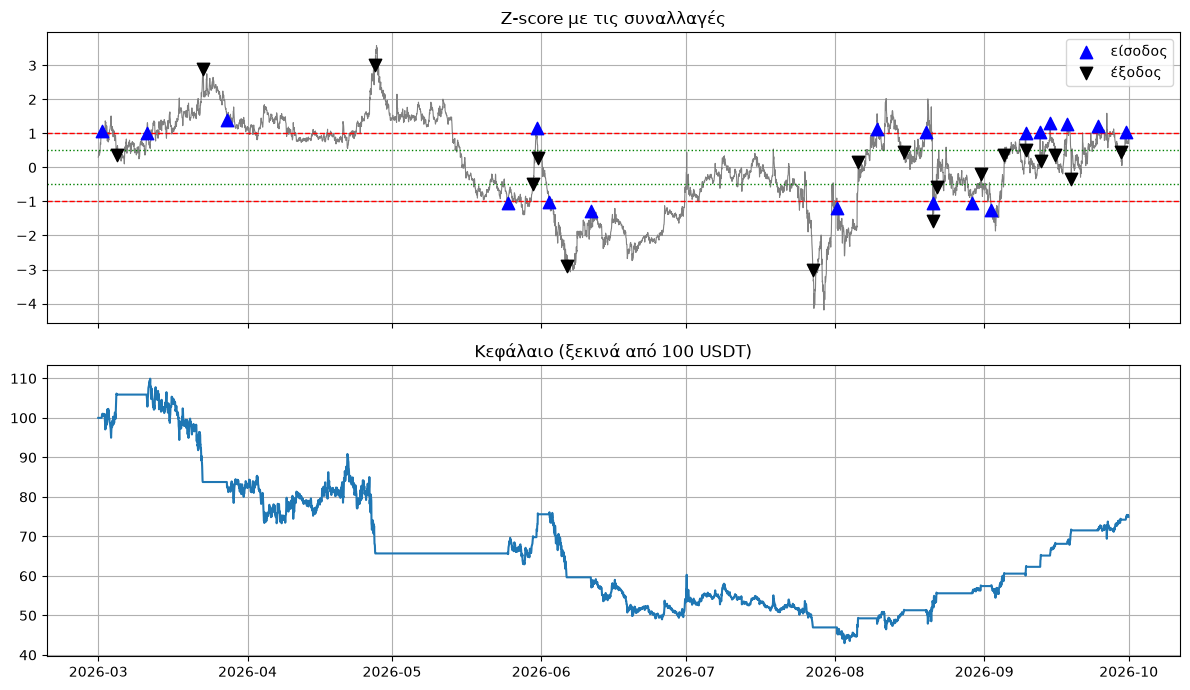

Τελικό κεφάλαιο: 74.94 USDT (-25.1%) | συναλλαγές: 19 | stop: 4 | fees: 2.50 | funding: 0.09


,είσοδος,θέση,Z εισόδου,έξοδος,λόγος,κέρδος (USDT)
0,03-01 18:00,SHORT A / LONG B,1.08,03-04 20:00,signal,5.90
1,03-11 02:00,SHORT A / LONG B,1.02,03-22 17:00,stop_loss,-22.13
2,03-27 18:00,SHORT A / LONG B,1.41,04-27 13:00,stop_loss,-18.08
3,05-25 02:00,LONG A / SHORT B,-1.04,05-30 08:00,signal,4.12
4,05-31 01:00,SHORT A / LONG B,1.17,05-31 08:00,signal,5.80
5,06-02 16:00,LONG A / SHORT B,-1.01,06-06 07:00,stop_loss,-15.96
6,06-11 08:00,LONG A / SHORT B,-1.28,07-27 10:00,stop_loss,-12.69
7,08-01 11:00,LONG A / SHORT B,-1.19,08-05 20:00,signal,2.30
8,08-09 18:00,SHORT A / LONG B,1.13,08-15 09:00,signal,2.05
9,08-19 22:00,SHORT A / LONG B,1.05,08-21 07:00,signal,2.13


In [7]:
res = run_backtest(data, params, cfg.strategy, cfg.costs, rc.test_start_ms, rc.test_end_ms, 100.0)
tr = res.trades_frame()
fig, axes = plt.subplots(2, 1, figsize=(12, 7), sharex=True)
axes[0].plot(t[i0:], z[i0:], lw=0.8, color="gray")
for s in (1, -1):
    axes[0].axhline(s * params.z_entry, color="r", ls="--", lw=1); axes[0].axhline(s * params.z_exit, color="g", ls=":", lw=1)
if len(tr):
    et = pd.to_datetime(tr["entry_ts"], unit="ms")
    axes[0].scatter(et, tr["z_entry"], marker="^", s=80, color="b", zorder=5, label="είσοδος")
    if "exit_ts" in tr:
        done = tr.dropna(subset=["exit_ts"])
        xt = pd.to_datetime(done["exit_ts"], unit="ms")
        axes[0].scatter(xt, np.interp(xt.astype("int64"), t.astype("int64"), z), marker="v", s=80, color="k", zorder=5, label="έξοδος")
    axes[0].legend()
axes[0].set_title("Z-score με τις συναλλαγές")
axes[1].plot(pd.to_datetime(res.ts, unit="ms"), res.equity); axes[1].set_title("Κεφάλαιο (ξεκινά από 100 USDT)")
plt.tight_layout(); plt.show()

m = res.metrics()
print(f"Τελικό κεφάλαιο: {m['FinalEquity']:.2f} USDT ({m['TotalRet']:+.1%}) | συναλλαγές: {m['Trades']} | "
      f"stop: {m['StopLosses']} | fees: {m['Fees']:.2f} | funding: {m['Funding']:.2f}")
if len(tr):
    show = pd.DataFrame({
        "είσοδος": pd.to_datetime(tr["entry_ts"], unit="ms").dt.strftime("%m-%d %H:%M"),
        "θέση": tr["side"].map({1: "LONG A / SHORT B", -1: "SHORT A / LONG B"}),
        "Z εισόδου": tr["z_entry"].round(2),
        "έξοδος": pd.to_datetime(tr.get("exit_ts"), unit="ms").dt.strftime("%m-%d %H:%M"),
        "λόγος": tr.get("reason"), "κέρδος (USDT)": tr.get("pnl", pd.Series(dtype=float)).round(2)})
    display(show)

## 9. Πώς διαλέχτηκαν τα ζεύγη (funnel)

Από εκατοντάδες νομίσματα προκύπτουν χιλιάδες πιθανά ζεύγη. Τα φιλτράρουμε σε 4 στάδια:
1. **Ιστορικό**: το νόμισμα πρέπει να υπάρχει τουλάχιστον 1000 μέρες
2. **Ίδιο blockchain**: π.χ. και τα δύο στο Ethereum (μοιράζονται χρήστες και ρευστότητα)
3. **Συσχέτιση**: οι τιμές να κινούνται μαζί (>0.9) και οι ωριαίες αποδόσεις επίσης (>0.5)
4. **Προβλεπτική ικανότητα (IC)**: όταν το Z είναι υψηλό, όντως πέφτει μετά; Κρατάμε τα 100 ζεύγη όπου αυτό ισχύει πιο έντονα

Μετά, για κάθε ζεύγος δοκιμάζουμε 60 συνδυασμούς παραμέτρων (L, z_entry, z_exit) στα **2 προηγούμενα χρόνια** και κρατάμε τον καλύτερο. Τέλος, τα ελέγχουμε σε **7 μήνες που δεν είχε δει** (περίοδος test).

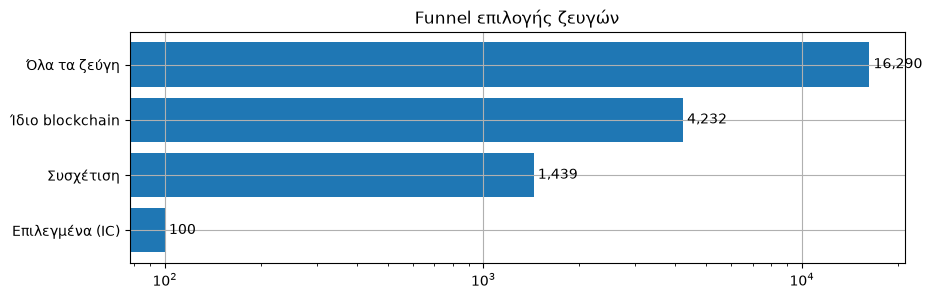

,a,b,chains,corr_logp,corr_ret,best_ic,best_lookback,best_horizon
0,BANDUSDT,OGNUSDT,ethereum,0.982663,0.670337,-0.379478,2160,168
1,SFPUSDT,SSVUSDT,ethereum,0.937385,0.549690,-0.379245,4320,168
2,ALICEUSDT,TUSDT,ethereum,0.957322,0.525064,-0.375252,4320,168
3,SFPUSDT,NKNUSDT,ethereum,0.957542,0.502561,-0.373041,2160,168
4,IOSTUSDT,ONEUSDT,binance-smart-chain,0.943355,0.736032,-0.371160,4320,168
5,YFIUSDT,SANDUSDT,base;ethereum;polygon-pos,0.980265,0.702920,-0.369734,4320,168
6,OGNUSDT,SKLUSDT,base;ethereum,0.987401,0.542010,-0.364041,4320,168
7,OGNUSDT,LRCUSDT,ethereum,0.986094,0.632499,-0.363311,720,168
8,BANDUSDT,CTSIUSDT,ethereum,0.980343,0.661534,-0.362622,2160,168
9,IOSTUSDT,ZILUSDT,binance-smart-chain,0.986774,0.753689,-0.361130,4320,168


In [8]:
counts = json.load(open("runs/hardened/funnel_counts.json"))
stages = {"Όλα τα ζεύγη": counts["filter1_pairs"], "Ίδιο blockchain": counts["filter2_pairs"],
          "Συσχέτιση": counts["filter3_pairs"], "Επιλεγμένα (IC)": counts["selected"]}
fig, ax = plt.subplots(figsize=(10, 3))
ax.barh(list(stages)[::-1], list(stages.values())[::-1], color="tab:blue")
for i, v in enumerate(list(stages.values())[::-1]): ax.text(v, i, f" {v:,}", va="center")
ax.set_xscale("log"); ax.set_title("Funnel επιλογής ζευγών"); plt.show()
display(pd.read_csv("runs/hardened/funnel.csv").head(10))

## 10. Το χαρτοφυλάκιο συνολικά (περίοδος test)

Όλα τα επιλεγμένα ζεύγη μαζί, με ίσο κεφάλαιο το καθένα. Συγκρίνουμε τις υποθέσεις του paper (`strict`, χωρίς ρεαλιστικά κόστη) με τις ρεαλιστικές (`hardened`, αυτές που τρέχει το bot).

strict (υποθέσεις paper)         Sharpe  2.61 | απόδοση +48.3% | max drawdown -12.1% | συναλλαγές 1114
hardened (ρεαλιστικά κόστη)      Sharpe  0.72 | απόδοση +5.6% | max drawdown -9.4% | συναλλαγές 874


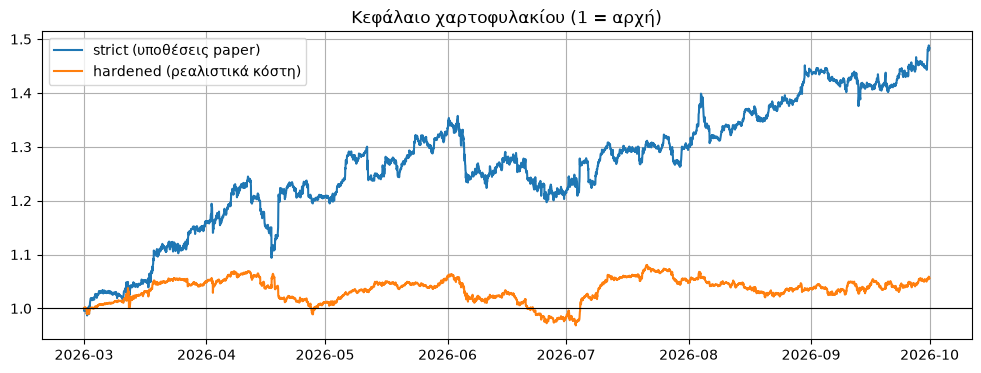

In [9]:
fig, ax = plt.subplots()
for tag, label in (("latest", "strict (υποθέσεις paper)"), ("hardened", "hardened (ρεαλιστικά κόστη)")):
    f = Path(f"runs/{tag}/portfolio_equity.csv")
    if f.exists():
        e = pd.read_csv(f); ax.plot(pd.to_datetime(e["ts"], unit="ms"), e["equity"] / e["equity"].iloc[0], label=label)
        mm = json.load(open(f"runs/{tag}/portfolio_metrics.json"))
        print(f"{label:32s} Sharpe {mm['Sharpe']:5.2f} | απόδοση {mm['TotalRet']:+.1%} | max drawdown {mm['MaxDD']:.1%} | συναλλαγές {mm['Trades']}")
ax.axhline(1, color="k", lw=0.8); ax.legend(); ax.set_title("Κεφάλαιο χαρτοφυλακίου (1 = αρχή)"); plt.show()

## 11. Το bot ζωντανά

Το paper bot γράφει ό,τι κάνει στη βάση `state/paper.db`. Τα επόμενα κελιά τη **διαβάζουν** χωρίς να την πειράζουν, οπότε μπορείς να τα τρέχεις όποτε θες ενώ δουλεύει το bot. Ξανατρέξε τα (Shift+Enter) για ενημέρωση.

Άλλοι τρόποι να το βλέπεις, από terminal:
- `python -m cryptopairs status`: σύνοψη (θέσεις, συναλλαγές, κέρδος)
- `tail -f logs/paper.log`: ζωντανή ροή του τι κάνει (Ctrl+C για έξοδο, το bot συνεχίζει)

In [10]:
db = Path("state/paper.db")
if not db.exists():
    print("Δεν υπάρχει ακόμα βάση: ξεκίνα το paper bot πρώτα.")
else:
    con = sqlite3.connect(f"file:{db}?mode=ro", uri=True)
    q = lambda sql: pd.read_sql_query(sql, con)
    ses = q("SELECT * FROM sessions ORDER BY started_at DESC LIMIT 1").iloc[0]
    print(f"Τελευταία συνεδρία: {ses['id']} | ξεκίνησε {pd.to_datetime(ses['started_at'], unit='ms'):%Y-%m-%d %H:%M} UTC | "
          f"{'τρέχει' if pd.isna(ses['ended_at']) else 'σταμάτησε'}")
    ps = q("SELECT * FROM pair_state")
    st = ps["strategy"].map(json.loads)
    ps["θέση"] = st.map(lambda s: {1: "LONG", -1: "SHORT", 0: "-"}[s["side"]])
    ps["κεφάλαιο"] = ps["book"].map(lambda b: json.loads(b)["cash"])
    ps["β"] = st.map(lambda s: s["beta"])
    ps["cooldown έως"] = st.map(lambda s: pd.to_datetime(s["cooldown_until"], unit="ms").strftime("%m-%d %H:%M") if s["cooldown_until"] > 0 else "")
    print(f"\nΑνοιχτές θέσεις: {(ps['θέση'] != '-').sum()} από {len(ps)} ζεύγη")
    display(ps[["pair_id", "θέση", "κεφάλαιο", "β", "z_entry", "z_exit", "cooldown έως"]])
    eq = q("SELECT * FROM equity ORDER BY bar_ts")
    if len(eq) > 1:
        fig, ax = plt.subplots(); ax.plot(pd.to_datetime(eq["bar_ts"], unit="ms"), eq["equity"]); ax.set_title("Κεφάλαιο paper bot"); plt.show()
    elif len(eq) == 1:
        print(f"Κεφάλαιο: {eq['equity'].iloc[-1]:.2f} USDT")
    trades = q("SELECT * FROM trades ORDER BY id DESC LIMIT 20")
    print(f"\nΤελευταίες συναλλαγές: {len(trades)}")
    if len(trades): display(trades[["pair_id", "side", "entry_ts", "exit_ts", "reason", "pnl", "fees"]])
    con.close()

Τελευταία συνεδρία: paper_20261001_112427_bdd4ce | ξεκίνησε 2026-10-01 11:24 UTC | τρέχει

Ανοιχτές θέσεις: 0 από 17 ζεύγη


,pair_id,θέση,κεφάλαιο,β,z_entry,z_exit,cooldown έως
0,BANDUSDT_OGNUSDT,-,100.0,None,3.0,0.5,
1,SFPUSDT_SSVUSDT,-,100.0,None,1.0,0.5,
2,ALICEUSDT_TUSDT,-,100.0,None,2.0,0.0,
3,IOSTUSDT_ONEUSDT,-,100.0,None,1.5,0.0,
4,YFIUSDT_SANDUSDT,-,100.0,None,0.8,0.5,
5,OGNUSDT_SKLUSDT,-,100.0,None,2.0,0.5,
6,BANDUSDT_CTSIUSDT,-,100.0,None,3.0,0.0,
7,IOSTUSDT_ZILUSDT,-,100.0,None,2.0,0.0,
8,BANDUSDT_GTCUSDT,-,100.0,None,2.0,0.0,
9,C98USDT_ARPAUSDT,-,100.0,None,2.0,0.5,



Τελευταίες συναλλαγές: 0


### Πόσο κοντά είναι κάθε ζεύγος σε είσοδο, αυτή τη στιγμή

Κατεβάζει τις τελευταίες τιμές από τη Binance (δημόσια δεδομένα, χωρίς κλειδιά) και υπολογίζει το τρέχον Z κάθε ζεύγους, ακριβώς όπως το bot. Όσο πιο κοντά είναι το |Z| στο όριο εισόδου, τόσο πιο κοντά είναι μια συναλλαγή. Παίρνει ~30 δευτερόλεπτα.

In [11]:
import ccxt
ex = ccxt.binanceusdm({"enableRateLimit": True}); ex.load_markets()

def closes(sym_id, n):
    sym = ex.markets_by_id[sym_id][0]["symbol"]
    since = ex.milliseconds() - (n + 2) * HOUR_MS; rows = []
    while True:
        r = ex.fetch_ohlcv(sym, "1h", since=since, limit=1500)
        if not r: break
        rows += r; since = r[-1][0] + HOUR_MS
        if len(r) < 1500: break
    s = pd.Series({x[0]: x[4] for x in rows}); return s.iloc[:-1]   # το τελευταίο κερί δεν έχει κλείσει

out, cache = [], {}
for x in pairs:
    try:
        for s in (x["a"], x["b"]):
            if s not in cache: cache[s] = closes(s, 4400)
        ab = pd.concat([cache[x["a"]], cache[x["b"]]], axis=1).dropna().iloc[-x["lookback"]:]
        a_, b_, s_ = fit_ols(np.log(ab.iloc[:, 0].values), np.log(ab.iloc[:, 1].values))
        zz = (np.log(ab.iloc[-1, 0]) - a_ - b_ * np.log(ab.iloc[-1, 1])) / s_
        out.append({"ζεύγος": x["id"], "Z τώρα": round(zz, 2), "όριο εισόδου": x["z_entry"],
                    "απόσταση": round(x["z_entry"] - abs(zz), 2), "β": round(b_, 3)})
    except Exception as e:
        out.append({"ζεύγος": x["id"], "Z τώρα": None, "όριο εισόδου": x["z_entry"], "απόσταση": None, "β": f"σφάλμα: {e}"[:40]})
live = pd.DataFrame(out).sort_values("απόσταση")
display(live)
print("απόσταση ≤ 0 → το ζεύγος είναι σε σήμα εισόδου (αν δεν έχει ήδη θέση ή cooldown)")

,ζεύγος,Z τώρα,όριο εισόδου,απόσταση,β
13,ARPAUSDT_OGNUSDT,4.55,2.0,-2.55,0.856
14,BANDUSDT_SKLUSDT,1.71,1.5,-0.21,0.762
15,TUSDT_GRTUSDT,-1.60,1.5,-0.10,0.258
4,IOSTUSDT_ONEUSDT,1.58,1.5,-0.08,0.421
17,SFPUSDT_ROSEUSDT,0.59,0.8,0.21,0.017
5,YFIUSDT_SANDUSDT,0.49,0.8,0.31,0.509
9,IOSTUSDT_ZILUSDT,1.60,2.0,0.40,0.598
16,HFTUSDT_ARBUSDT,1.06,1.5,0.44,0.435
1,SFPUSDT_SSVUSDT,-0.50,1.0,0.50,0.395
11,C98USDT_ARPAUSDT,-1.37,2.0,0.63,0.914


απόσταση ≤ 0 → το ζεύγος είναι σε σήμα εισόδου (αν δεν έχει ήδη θέση ή cooldown)
